# EN3160 Assignment 2 on Fitting and Alignment

Assignment Done and Submitted by: O.N.H. Imaduwage 230258D 

Github Link:
https://github.com/oshan-imaduwage/EN3160_Assignment_02


### Q1

Range of sigma values used: [1.00, 10.00] across 10 scales
Total blobs detected: 56

Top 3 Largest Circles Detected:
 1. Center: (x=282, y=338), Radius: 9.90 px, Sigma: 7.00
 2. Center: (x=0, y=275), Radius: 9.90 px, Sigma: 7.00
 3. Center: (x=106, y=255), Radius: 8.49 px, Sigma: 6.00


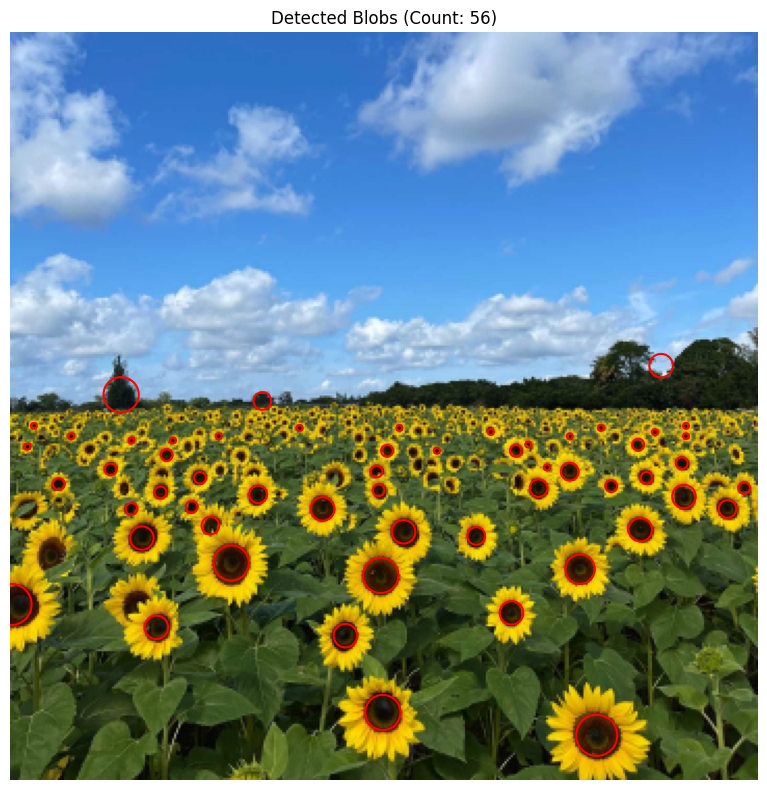

In [1]:
import cv2
import numpy as np
import math
import matplotlib.pyplot as plt

im1 = cv2.imread('images/the_berry_farms_sunflower_field.jpeg', cv2.IMREAD_REDUCED_COLOR_4)
assert im1 is not None

def LoG(sigma):
    half_size = int(np.ceil(3 * sigma))
    y, x = np.ogrid[-half_size:half_size + 1, -half_size:half_size + 1]

    r2 = x**2 + y**2
    sigma2 = sigma**2
    gaussian = np.exp(-r2 / (2.0 * sigma2))
    log_kernel = (1.0 / (np.pi * sigma2)) * ((r2 / (2.0 * sigma2)) - 1.0) * gaussian

    log_kernel -= np.mean(log_kernel)

    return log_kernel

H, W, colors = im1.shape
sigmas = [1,2,3,4,5,6,7,8,9,10]

scale_space = np.zeros((len(sigmas), H, W), dtype=np.float64)

im1_normalised = im1.astype(np.float64) / 255.0

for i, sigma in enumerate(sigmas):
    kernel = LoG(sigma)
    response = cv2.filter2D(
        src=im1_normalised, 
        ddepth=cv2.CV_64F, 
        kernel=kernel, 
        borderType=cv2.BORDER_REFLECT
    )    
    scale_space[i] = np.mean(np.square(response), axis=2)

num_scales, H, W = scale_space.shape

structuring_element = np.ones((3, 3), dtype=np.uint8)
spatial_max = np.zeros_like(scale_space)

for i in range(num_scales):
    spatial_max[i] = cv2.dilate(scale_space[i], kernel=structuring_element)

padded_spatial_max = np.pad(
        spatial_max, 
        pad_width=((1, 1), (0, 0), (0, 0)), 
        mode='constant', 
        constant_values=0.0
    )

local_max_3d = np.maximum.reduce([
        padded_spatial_max[:-2],   
        padded_spatial_max[1:-1],  
        padded_spatial_max[2:]    
    ])

## here i picked the threshold value after testing for a visually pleasing result
is_extremum = (scale_space == local_max_3d) & (scale_space > 0.08)

scale_indices, y_indices, x_indices = np.where(is_extremum)
    
blobs = []
for s_idx, y, x in zip(scale_indices, y_indices, x_indices):
    sigma = sigmas[s_idx]
    radius = sigma * np.sqrt(2)
    response_strength = scale_space[s_idx, y, x]    
    blobs.append((y, x, sigma, radius, response_strength))

blobs.sort(key=lambda b: (b[3], b[4]), reverse=True)

print(f"Range of sigma values used: [{sigmas[0]:.2f}, {sigmas[-1]:.2f}] across {len(sigmas)} scales")
print(f"Total blobs detected: {len(blobs)}\n")
print("Top 3 Largest Circles Detected:")
for idx, (y, x, sigma, radius, strength) in enumerate(blobs[:3], 1):
    print(f" {idx}. Center: (x={x}, y={y}), Radius: {radius:.2f} px, Sigma: {sigma:.2f}")

from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(8, 8))

im1 = cv2.cvtColor(im1, cv2.COLOR_BGR2RGB)
ax.imshow(im1, cmap='gray')

for y, x, sigma, radius, _ in blobs:
    circle = Circle((x, y), radius, color='red', linewidth=1.5, fill=False)
    ax.add_patch(circle)
    
ax.set_title(f"Detected Blobs (Count: {len(blobs)})")
ax.axis('off')
plt.tight_layout()
plt.show()


##need to add explanation of result and code

### Q2

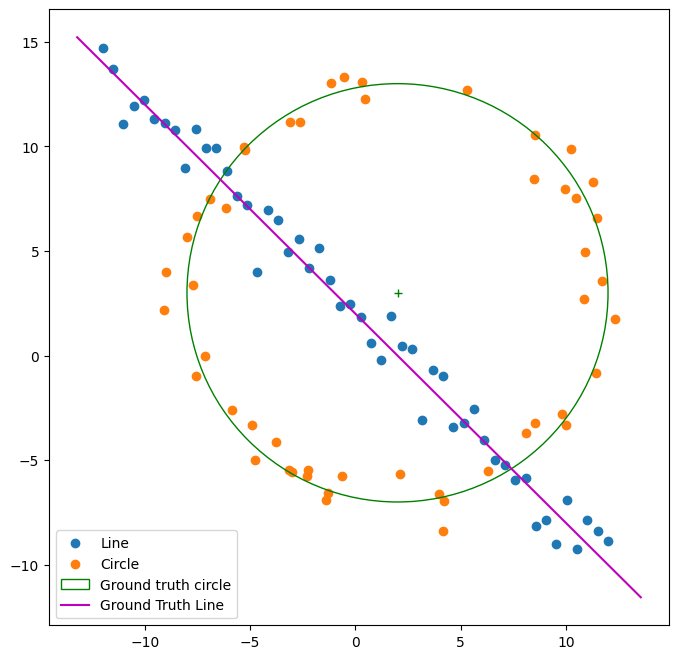

In [2]:
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt
import matplot2tikz as tikzplotlib
# np . random . seed ( 0 )
N = 100
half_n = N//2
r = 10
x0_gt , y0_gt = 2 , 3 # Center
s = r/16
t = np.random.uniform( 0, 2*np.pi, half_n )
n = s*np.random.randn( half_n )
x , y = x0_gt + (r+n)*np.cos(t), y0_gt + (r+n)*np.sin(t)
X_circ= np.hstack( ( x.reshape( half_n,1 ) , y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace( -12, 12, half_n )
y = m*x + b + s*np.random.randn( half_n )
X_line = np.hstack( ( x.reshape( half_n , 1 ), y.reshape( half_n , 1 ) ) )
X = np.vstack( ( X_circ , X_line ) )
fig, ax = plt.subplots(1,1, figsize = ( 8 , 8 ) )
ax.scatter( X_line [ : , 0 ] , X_line [ : , 1 ] , label = 'Line' )
ax.scatter( X_circ[ : , 0 ] , X_circ[ : , 1 ] , label = 'Circle')
circle_gt = plt.Circle( ( x0_gt , y0_gt ) , r , color = 'g', fill=False , label = 'Ground truth circle' )
ax.add_patch(circle_gt)
ax.plot(( x0_gt ) , ( y0_gt ) , '+' , color = 'g' )
x_min, x_max = ax.get_xlim( )
x_ = np.array([x_min , x_max])
y_ = m*x_ + b
plt.plot( x_ , y_ , color = 'm' , label= 'Ground Truth Line' )
plt.legend( )